# Balls

#TODO:

      2 - Test parameters for angle, top, and side. Check if resizing makes difference

      3- Test all images in the set a put results in a results folder

      4 - Test with table angle to the other side (not in development set)


In [186]:
from dataclasses import dataclass
from typing import Any

@dataclass
class ImageState:
    # Images
    hsv_image: Any = None
    hsv_image_shadow_masked: Any = None
    
    # Median values
    h_med: Any = None
    s_med: Any = None
    v_med: Any = None
    
    # Angles
    is_top: Any = None
    is_front: Any = None
    is_angle: Any = None      
    is_angle_r: Any = None
    is_angle_l: Any = None
    
    # Lines
    top_line_outer_full: Any = None
    top_line_inner_full: Any = None
    side_line_l_inner_full: Any = None
    side_line_l_outer_full: Any = None
    side_line_r_inner_full: Any = None
    side_line_r_outer_full: Any = None
    bot_line_inner_full: Any = None
    
    # Corner points
    tl_inner: Any = None
    tl_outer: Any = None
    tr_inner: Any = None
    tr_outer: Any = None
    br_inner: Any = None
    br_outer: Any = None
    bl_inner: Any = None
    bl_outer: Any = None

state = ImageState()

In [187]:
from pathlib import Path
import sys

import cv2
import itertools
import math

import matplotlib.pyplot as plt
import numpy as np

# Make `vc-proj/` importable when running from `vc-proj/notebooks/`
cwd = Path.cwd().resolve()
project_root = cwd if (cwd / "src").exists() else cwd.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.main import (
    get_lines,
    get_inner_outer_lines,
    get_intersections,
    got_angle,
    order_points_by_angle,
)

In [232]:
DATA_DIR = Path("./../data")

#IMAGE_PATH = DATA_DIR / "development_set/5a_png.rf.bae1d48b3d2d96a990799b836ecebcbb.jpg"
#IMAGE_PATH = DATA_DIR / "development_set/16a_png.rf.e7f801e6e3e47469fbbd3bdd34677025.jpg" #<---- Problem: it's the same color on bottom just use MANSUR functions to find lines and cut with outer line
#IMAGE_PATH = DATA_DIR / "development_set/19a_png.rf.dd2935e517f1adfcd0a735f3f937fa02.jpg" #This one too
#IMAGE_PATH = DATA_DIR / "development_set/32_png.rf.1edd41098eb074d061f00c09470d90cf.jpg"
IMAGE_PATH = DATA_DIR / "development_set/3f_png.rf.81c7e132365ef95bb19380ca389025f6.jpg"#
#IMAGE_PATH = DATA_DIR / "development_set/34_png.rf.407889c8b2afe2a57c57461fa46b2d4f.jpg"

#IMAGE_PATH = DATA_DIR / "development_set/91_png.rf.d78bae1b26a617eb6363e4345800eb54.jpg"

In [233]:


def get_center_mode_hsv(hsv_img, area_ratio=0.20):
    """
    Crops the center of the image to the specified area ratio 
    and returns the most frequent H, S, and V values.
    """
    h, w = hsv_img.shape[:2]
 
    scale = np.sqrt(area_ratio)
    crop_w = int(w * scale)
    crop_h = int(h * scale)
    cx, cy = w // 2, h // 2
    start_x = cx - (crop_w // 2)
    start_y = cy - (crop_h // 2)
    center_crop = hsv_img[start_y:start_y + crop_h, start_x:start_x + crop_w]
    
    H, S, V = cv2.split(center_crop)
    
    h_mode = np.argmax(np.bincount(H.flatten()))
    s_mode = np.argmax(np.bincount(S.flatten()))
    v_mode = np.argmax(np.bincount(V.flatten()))
    
    return int(h_mode), int(s_mode), int(v_mode)



In [234]:
image = cv2.imread(str(IMAGE_PATH))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
state.hsv_image = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

Most frequent HSV in the center 20%: H=103, S=162, V=221


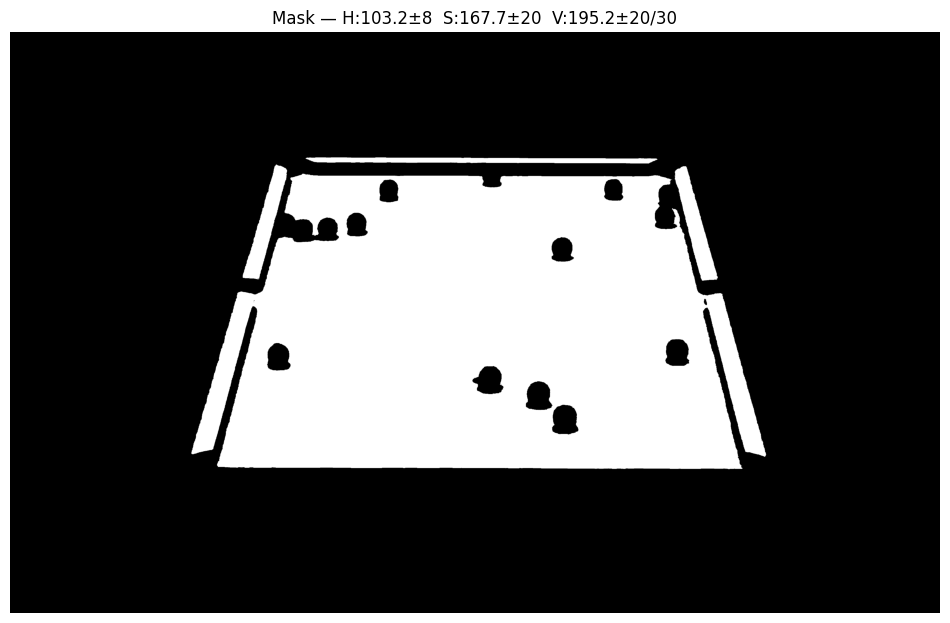

In [235]:
#Values for second mask
state.h_med = 103.2
state.s_med = 167.7   
state.v_med = 195.2

# Shadows values sampled
shadow_h = 106.1
shadow_s = 202.8
shadow_v = 97.4

dark_cloth_h = 101
dark_cloth_s = 214
dark_cloth_v = 217


# Define tolerance around the median values
h_tol = 8
s_tol = 20
v_tol_up = 20      

v_tol_down = 30

h_freq, s_freq, v_freq = get_center_mode_hsv(state.hsv_image, area_ratio=0.20)

print(f"Most frequent HSV in the center 20%: H={h_freq}, S={s_freq}, V={v_freq}")



lower_blue = np.array([h_freq - h_tol, s_freq- s_tol, v_freq - v_tol_down])
upper_blue = np.array([h_freq + h_tol, s_freq + s_tol, v_freq + v_tol_up])

# Clip to valid HSV ranges
lower_blue = np.clip(lower_blue, [0, 0, 0], [179, 255, 255])
upper_blue = np.clip(upper_blue, [0, 0, 0], [179, 255, 255])


mask_table = cv2.inRange(state.hsv_image, lower_blue, upper_blue)



plt.figure(figsize=(12, 8))
plt.imshow(mask_table, cmap='gray')
plt.axis('off')
plt.title(f'Mask — H:{state.h_med}±{h_tol}  S:{state.s_med}±{s_tol}  V:{state.v_med}±{v_tol_up}/{v_tol_down}')
plt.show()

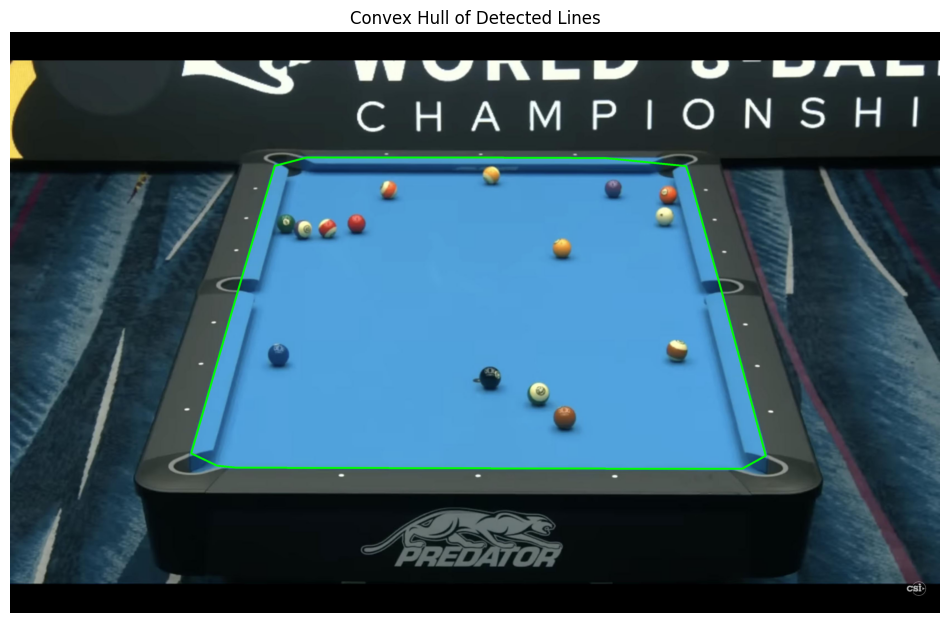

In [236]:
edges = cv2.Canny(mask_table, 50, 150)

lines = cv2.HoughLinesP(
    edges,
    1,
    np.pi / 180,
    threshold=80,
    minLineLength=100,
    maxLineGap=80
)

tmp_lines = []
for line in lines:
    x1, y1, x2, y2 = line[0]
    length = math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)
    if length >= 250:
        tmp_lines.append(line)
lines = tmp_lines

pts = []
for line in lines:
    x1, y1, x2, y2 = line[0]
    pts.append((x1, y1))
    pts.append((x2, y2))

pts = np.array(pts)
hull = cv2.convexHull(pts)

line_image = image.copy()
cv2.polylines(line_image, [hull], isClosed=True, color=(0, 255, 0), thickness=5)

plt.figure(figsize=(12, 8))
plt.imshow(line_image)
plt.axis('off')
plt.title('Convex Hull of Detected Lines')
plt.show()

In [237]:
def make_line(p1, p2):
    p1 = np.array(p1, dtype=np.float32)
    p2 = np.array(p2, dtype=np.float32)

    A = p1[1] - p2[1]
    B = p2[0] - p1[0]
    C = p1[0]*p2[1] - p2[0]*p1[1]

    return A, B, C

In [238]:
def is_above_line(pt, line):
    x, y = pt
    A, B, C = line
    y_line = -(A * x + C) / B
    return y < y_line

In [239]:
def shadow_mask_borders(state):
    cloth_color = np.array([state.h_med, state.s_med, state.v_med], dtype=np.float32)
    threshold = 90 
    height, width = state.hsv_image.shape[:2]
    h_channel = state.hsv_image[:, :, 0]
    s_channel = state.hsv_image[:, :, 1]
    v_channel = state.hsv_image[:, :, 2]

    #Defines sampled values for shadows and cloth with bigger tolerances
    is_dark_shadow = (        
        (h_channel >= 95) & (h_channel <= 115) &  
        (s_channel > 184) &                        
        (v_channel < 114)                          
    )   

    h_tol = 6
    s_tol_up = 10
    s_tol_down = 40
    v_tol_up = 50
    v_tol_down = 200

    lower_blue = np.array([state.h_med - h_tol, state.s_med - s_tol_down, state.v_med - v_tol_down])
    upper_blue = np.array([state.h_med + h_tol, state.s_med + s_tol_up, state.v_med + v_tol_up])

    lower_blue = np.clip(lower_blue, [0, 0, 0], [179, 255, 255])
    upper_blue = np.clip(upper_blue, [0, 0, 0], [179, 255, 255])

    xx, yy = np.meshgrid(np.arange(width), np.arange(height))
    coords = np.stack([xx.ravel(), yy.ravel()], axis=-1)

    #Defines cut regions between top and side lines (in case of angled views)
    A, B, C = state.top_line_inner_full
    y_line = -(A * coords[:, 0] + C) / B
    mask_line_flat = coords[:, 1] < y_line
    mask_line = mask_line_flat.reshape(height, width)

    mask_x = (xx >= state.tl_outer[0]) & (xx <= state.tr_outer[0])
    top_spatial_region = mask_line & mask_x
    final_side_mask = np.zeros((height, width), dtype=bool)

    if state.is_angle_l:
        print("Table is leaning left.")
        A_out, B_out, C_out = state.side_line_r_outer_full
        A_in, B_in, C_in = state.side_line_r_inner_full

        x_line_r_outer = -(B_out * coords[:, 1] + C_out) / A_out
        x_line_r_inner = -(B_in * coords[:, 1] + C_in) / A_in
        
        mask_side_combined_flat = (coords[:, 0] > x_line_r_inner) & (coords[:, 0] < x_line_r_outer)
        final_side_mask = mask_side_combined_flat.reshape(height, width)

    elif state.is_angle_r:
        print("Table is leaning right.")
        A_out, B_out, C_out = state.side_line_l_outer_full
        A_in, B_in, C_in = state.side_line_l_inner_full

        x_line_l_outer = -(B_out * coords[:, 1] + C_out) / A_out
        x_line_l_inner = -(B_in * coords[:, 1] + C_in) / A_in
        
        mask_side_combined_flat = (coords[:, 0] > x_line_l_outer) & (coords[:, 0] < x_line_l_inner)
        final_side_mask = mask_side_combined_flat.reshape(height, width)

    #Replace this regions by uniform blue (cloth color) 
    all_spatial_regions = top_spatial_region | final_side_mask
    diff = np.linalg.norm(state.hsv_image.astype(np.float32) - cloth_color, axis=2)
    mask_color_old = diff <= threshold
    mask_strict_new = cv2.inRange(state.hsv_image, lower_blue, upper_blue) > 0
    all_valid_colors = is_dark_shadow | mask_color_old | mask_strict_new
    mask_final = all_spatial_regions & all_valid_colors

    state.hsv_image_shadow_masked = state.hsv_image.copy()
    state.hsv_image_shadow_masked[mask_final] = [state.h_med, state.s_med, state.v_med]

    return state.hsv_image_shadow_masked

In [240]:
def patch_corner_holes(state):
    distance_tl = np.linalg.norm(state.tl_inner - state.tl_outer)
    distance_tr = np.linalg.norm(state.tr_inner - state.tr_outer)
    distance_br = np.linalg.norm(state.br_inner - state.br_outer)
    distance_bl = np.linalg.norm(state.bl_inner - state.bl_outer)

    tl_hole=(state.tl_inner+state.tl_outer)/2
    tr_hole=(state.tr_inner+state.tr_outer)/2
    br_hole=(state.br_inner+state.br_outer)/2
    bl_hole=(state.bl_inner+state.bl_outer)/2

    circle_hsv_color = (state.h_med, state.s_med, state.v_med) 

    tl = (int(tl_hole[0]), int(tl_hole[1]))
    tr = (int(tr_hole[0]), int(tr_hole[1]))
    br = (int(br_hole[0]), int(br_hole[1]))
    bl = (int(bl_hole[0]), int(bl_hole[1]))

    cv2.circle(state.hsv_image_shadow_masked, tl, int(distance_tl/2), circle_hsv_color, 1) #just line for top
    cv2.circle(state.hsv_image_shadow_masked, tr, int(distance_tr/2), circle_hsv_color, 1)
    cv2.circle(state.hsv_image_shadow_masked, br, int(distance_br/2)+10, circle_hsv_color, -1) #fill for bottom
    cv2.circle(state.hsv_image_shadow_masked, bl, int(distance_bl/2)+10, circle_hsv_color, -1)

    height, width = state.hsv_image_shadow_masked.shape[:2]
    xx, yy = np.meshgrid(np.arange(width), np.arange(height))
    coords = np.stack([xx.ravel(), yy.ravel()], axis=-1)

    # Line Mask 
    A, B, C = state.top_line_inner_full
    y_line = -(A * coords[:, 0] + C) / B
    mask_line_flat = coords[:, 1] < y_line 

    # Circle Masks
    # Calculate circle radius based on distances between inner and outer points, with some padding
    radius_tl = int(distance_tl/2) +25
    radius_tr = int(distance_tr/2) + 30

    # Create boolean masks for points inside the top-left and top-right circles
    mask_circle_tl_flat = (coords[:, 0] - tl[0])**2 + (coords[:, 1] - tl[1])**2 <= radius_tl**2
    mask_circle_tr_flat = (coords[:, 0] - tr[0])**2 + (coords[:, 1] - tr[1])**2 <= radius_tr**2

    mask_top_circles_flat = mask_circle_tl_flat | mask_circle_tr_flat

    # Combine Line and Circle Conditions
    # The point must be above the line and inside one of the top circles
    final_mask_flat = mask_line_flat & mask_top_circles_flat
    final_mask = final_mask_flat.reshape(height, width)

    state.hsv_image_shadow_masked[final_mask] = [state.h_med, state.s_med, state.v_med]

    #patch holes in top view
    if state.is_top:
        cv2.circle(state.hsv_image_shadow_masked, (int(state.tl_outer[0]), int(state.tl_outer[1])), int(distance_tl/2)+50, circle_hsv_color, -1)
        cv2.circle(state.hsv_image_shadow_masked, (int(state.tr_outer[0]), int(state.tr_outer[1])), int(distance_tr/2)+50, circle_hsv_color, -1)
        cv2.circle(state.hsv_image_shadow_masked, (int(state.br_outer[0]), int(state.br_outer[1])), int(distance_br/2)+50, circle_hsv_color, -1)
        cv2.circle(state.hsv_image_shadow_masked, (int(state.bl_outer[0]), int(state.bl_outer[1])), int(distance_bl/2)+50, circle_hsv_color, -1)
        mid_point_upper = ((state.tl_outer + state.tr_outer) / 2).astype(int)
        mid_point_lower = ((state.bl_outer + state.br_outer) / 2).astype(int)
        cv2.circle(state.hsv_image_shadow_masked, (mid_point_upper[0], mid_point_upper[1]), int(distance_tl/2)+50, circle_hsv_color, -1)
        cv2.circle(state.hsv_image_shadow_masked, (mid_point_lower[0], mid_point_lower[1]), int(distance_tl/2)+50, circle_hsv_color, -1)
    
    #patch holes and sides in front view
    if state.is_front:
        A_out, B_out, C_out = state.side_line_r_outer_full
        A_in, B_in, C_in = state.side_line_r_inner_full

        y_line_r_outer = -(A_out * coords[:, 0] + C_out) / B_out
        y_line_r_inner = -(A_in * coords[:, 0] + C_in) / B_in
        
        A_out_l, B_out_l, C_out_l = state.side_line_l_outer_full
        A_in_l, B_in_l, C_in_l = state.side_line_l_inner_full

        y_line_l_outer = -(A_out_l * coords[:, 0] + C_out_l) / B_out_l
        y_line_l_inner = -(A_in_l * coords[:, 0] + C_in_l) / B_in_l

        mask_above_inner_flat_l = coords[:, 1] < y_line_l_inner
        mask_below_outer_flat_l = coords[:, 1] > y_line_l_outer

        mask_above_inner_flat = coords[:, 1] < y_line_r_inner
        mask_below_outer_flat = coords[:, 1] > y_line_r_outer
        
        mask_side_combined_flat = (mask_above_inner_flat & mask_below_outer_flat) | (mask_above_inner_flat_l & mask_below_outer_flat_l) 
        final_side_mask = mask_side_combined_flat.reshape(height, width)

        state.hsv_image_shadow_masked[final_side_mask] = [state.h_med, state.s_med, state.v_med]



    return state.hsv_image_shadow_masked

In [241]:
#Get lines, edges, corners points, and view angle

lines = get_lines(mask_table, min_length=250)
edge_points = [line[0] for line in lines]
center = [((x1 + x2) // 2, (y1 + y2) // 2) for (x1, y1, x2, y2) in edge_points]
center = np.mean(center, axis=0).astype(int)

inner_lines, outer_lines = get_inner_outer_lines(lines, center, mask_table)
intersection_points_outer = get_intersections(outer_lines, image.shape[0], image.shape[1])
intersection_points_inner = get_intersections(inner_lines, image.shape[0], image.shape[1])

pts_ordered_outer, pts_ordered_inner, angles, order = order_points_by_angle(intersection_points_outer, intersection_points_inner)
state.is_top, state.is_front, state.is_angle, _ = got_angle(pts_ordered_outer)

print(f"Is top view: {state.is_top}, Is front view: {state.is_front}, Is angle view: {state.is_angle}")
for i, pt in enumerate(pts_ordered_outer):
    print(f"Outer Point {i}: {pt}, Angle: {angles[i]:.2f} degrees")

state.tl_inner = pts_ordered_inner[0]
state.tr_inner = pts_ordered_inner[1]
state.br_inner = pts_ordered_inner[2]
state.bl_inner = pts_ordered_inner[3]
state.tl_outer = pts_ordered_outer[0]
state.tr_outer = pts_ordered_outer[1]
state.br_outer = pts_ordered_outer[2]
state.bl_outer = pts_ordered_outer[3]

state.top_line_outer_full = make_line(state.tl_outer, state.tr_outer)
state.top_line_inner_full = make_line(state.tl_inner, state.tr_inner)
state.side_line_r_outer_full = make_line(state.tr_outer, state.br_outer)
state.side_line_r_inner_full = make_line(state.tr_inner, state.br_inner)
state.side_line_l_outer_full = make_line(state.tl_outer, state.bl_outer)
state.side_line_l_inner_full = make_line(state.tl_inner, state.bl_inner)
state.bot_line_inner_full = make_line(state.bl_inner, state.br_inner)

Is top view: False, Is front view: True, Is angle view: False
Outer Point 0: [961.1078 456.    ], Angle: -0.65 degrees
Outer Point 1: [2440.733  456.   ], Angle: 0.49 degrees
Outer Point 2: [2742.6353 1579.    ], Angle: -2.49 degrees
Outer Point 3: [ 638.32935 1579.     ], Angle: 2.65 degrees


Shadow mask and patch corner holes using semi-circle around mid points of inner and outer corners and above inner line


In [242]:
#Appy shadow_masks to edges according to view angle

state.is_angle_l = state.is_angle and state.tl_outer[0] < state.bl_outer[0]
state.is_angle_r = state.is_angle and state.tl_outer[0] > state.bl_outer[0]

state.hsv_image_shadow_masked = shadow_mask_borders(state)
state.hsv_image_shadow_masked = patch_corner_holes(state)


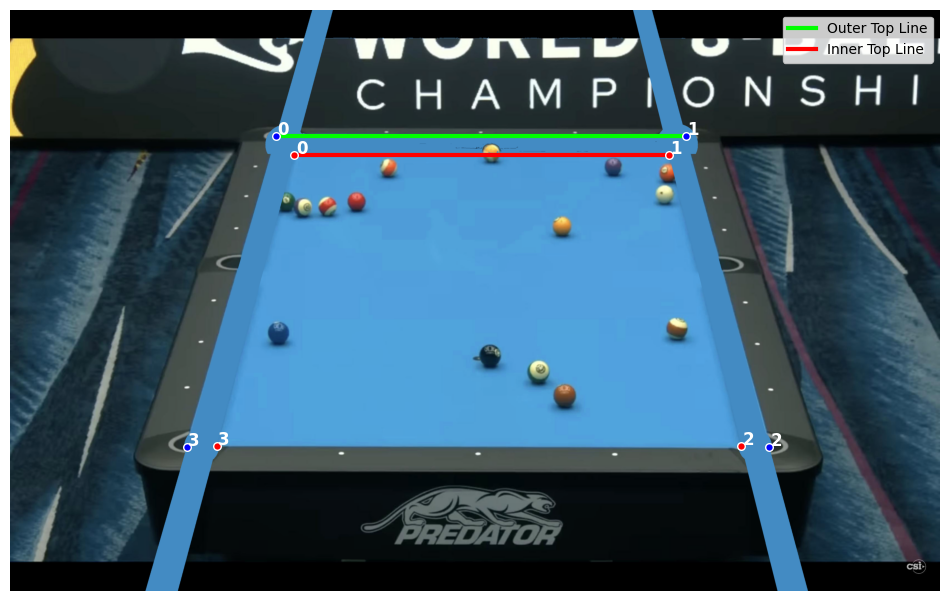

In [243]:
plt.figure(figsize=(12, 8))
rgb_image = cv2.cvtColor(state.hsv_image_shadow_masked, cv2.COLOR_HSV2RGB)
plt.imshow(rgb_image)
x_outer = [state.tl_outer[0], state.tr_outer[0]]
y_outer = [state.tl_outer[1], state.tr_outer[1]]
plt.plot(x_outer, y_outer, color='lime', linewidth=3, label='Outer Top Line')
x_inner = [state.tl_inner[0], state.tr_inner[0]]
y_inner = [state.tl_inner[1], state.tr_inner[1]]
plt.plot(x_inner, y_inner, color='red', linewidth=3, label='Inner Top Line')
for i, (x, y) in enumerate(pts_ordered_outer):
    plt.scatter(x, y, color='blue', s=30, edgecolors='white', zorder=5)
    plt.text(x + 5, y - 5, str(i), color='white', fontsize=12, weight='bold', zorder=6)
for i, (x, y) in enumerate(pts_ordered_inner):
    plt.scatter(x, y, color='red', s=30, edgecolors='white', zorder=5)
    plt.text(x + 5, y - 5, str(i), color='white', fontsize=12, weight='bold', zorder=6)
plt.axis('off')
plt.legend()
plt.show()

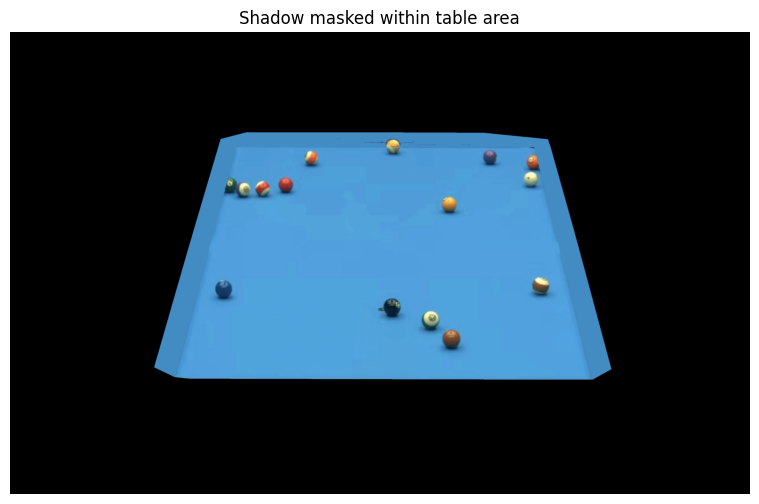

In [244]:

mask_hull = np.zeros(state.hsv_image_shadow_masked.shape, dtype=np.uint8)
cv2.fillPoly(mask_hull, [hull], (255, 255, 255))
masked_image = cv2.bitwise_and(state.hsv_image_shadow_masked, mask_hull)
display_image = cv2.cvtColor(masked_image, cv2.COLOR_HSV2RGB)


plt.figure(figsize=(10, 6))
plt.imshow(display_image)
plt.title('Shadow masked within table area')
plt.axis('off')
plt.show()



Here two different masks are applied according to cloth color. This is hard coded for dark tables 

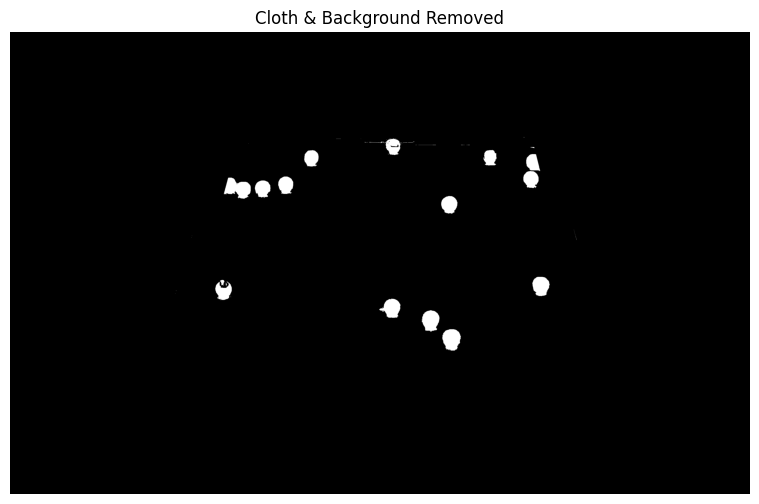

In [245]:
import math


dark_cloth_h = 101
dark_cloth_s = 214
dark_cloth_v = 217

dist_to_state = math.hypot(s_freq - state.s_med, v_freq - state.v_med)
dist_to_dark = math.hypot(s_freq - dark_cloth_s, v_freq - dark_cloth_v)

d_h_tol = 6
d_s_tol = 35
d_v_tol_up = 40

d_v_tol_down = 60

lower_dark_blue = np.array([dark_cloth_h - d_h_tol, dark_cloth_s - d_s_tol, dark_cloth_v - d_v_tol_down])
upper_dark_blue = np.array([dark_cloth_h + d_h_tol, dark_cloth_s + d_s_tol, dark_cloth_v + d_v_tol_up])

lower_dark_blue = np.clip(lower_dark_blue, [0, 0, 0], [179, 255, 255])
upper_dark_blue = np.clip(upper_dark_blue, [0, 0, 0], [179, 255, 255])

mask_dark_cloth = cv2.inRange(masked_image, lower_dark_blue, upper_dark_blue)

if dist_to_state < dist_to_dark:
    h_tol = 6
    s_tol_up = 10
    s_tol_down = 40
    v_tol_up = 50
    v_tol_down = 80

    lower_blue = np.array([state.h_med - h_tol, state.s_med - s_tol_down, state.v_med - v_tol_down])
    upper_blue = np.array([state.h_med + h_tol, state.s_med + s_tol_up, state.v_med + v_tol_up])

    lower_blue = np.clip(lower_blue, [0, 0, 0], [179, 255, 255])
    upper_blue = np.clip(upper_blue, [0, 0, 0], [179, 255, 255])
    
    mask_cloth = cv2.inRange(masked_image, lower_blue, upper_blue)
    combined_cloth = cv2.bitwise_or(mask_cloth, mask_dark_cloth)
else:
    combined_cloth = mask_dark_cloth

lower_any_color = np.array([0, 0, 1])
upper_any_color = np.array([179, 255, 255])
mask_not_black = cv2.inRange(masked_image, lower_any_color, upper_any_color)
mask_inverted_cloth = cv2.bitwise_not(combined_cloth)
mask = cv2.bitwise_and(mask_inverted_cloth, mask_not_black)

mask_hull = np.zeros(masked_image.shape[:2], dtype=np.uint8)
cv2.fillPoly(mask_hull, [hull], 255)

mask = cv2.bitwise_and(mask, mask_hull)

#gray_mask = cv2.medianBlur(mask, 9)
#gray_mask = cv2.GaussianBlur(mask, (5, 5), 2)

plt.figure(figsize=(12, 6))
plt.imshow(mask, cmap='gray')
plt.title('Cloth & Background Removed')
plt.axis('off')
plt.show()

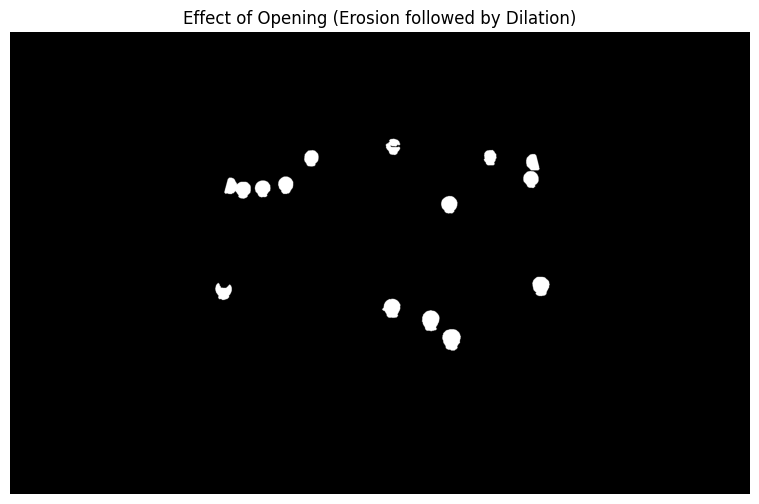

In [246]:

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3,3))

eroded_mask = cv2.dilate(mask, kernel, iterations=6)
eroded_mask = cv2.erode(eroded_mask, kernel, iterations=6)

eroded_mask = cv2.erode(mask, kernel, iterations=6)
opened_mask = cv2.dilate(eroded_mask, kernel, iterations=6)

plt.figure(figsize=(12, 6))
plt.imshow(opened_mask, cmap='gray')
plt.title('Effect of Opening (Erosion followed by Dilation)')
plt.axis('off')
plt.show()

In [247]:
opened_mask_blurred = cv2.medianBlur(opened_mask, 7)

False False
Found 18 circle(s) initially
Total valid balls drawn on screen: 18
Balls flagged as overlaps: 6
--> FINAL BALL COUNT (smaller overlaps removed): 15


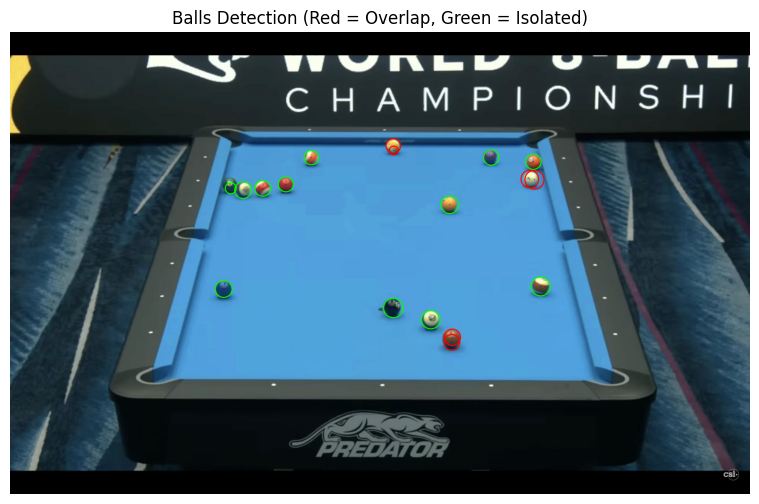

In [248]:

def calculate_overlap_area(c1, c2):
    """Calculates the exact area of intersection between two circles."""
    x1, y1, r1 = c1
    x2, y2, r2 = c2
    d = math.hypot(x2 - x1, y2 - y1)
    
    #No overlap
    if d >= r1 + r2:
        return 0.0
        
    # One circle is inside the other
    if d <= abs(r1 - r2):
        return math.pi * min(r1, r2)**2
        
    #  Partial overlap 
    r1_sq, r2_sq = r1**2, r2**2
    d_sq = d**2
    
    #  areas
    part1 = r1_sq * math.acos((d_sq + r1_sq - r2_sq) / (2 * d * r1))
    part2 = r2_sq * math.acos((d_sq + r2_sq - r1_sq) / (2 * d * r2))
    
    # Triangle areas to subtract
    part3 = 0.5 * math.sqrt((-d + r1 + r2) * (d + r1 - r2) * (d - r1 + r2) * (d + r1 + r2))
    
    return part1 + part2 - part3

print(state.is_angle_l, state.is_angle_r)
if(state.is_angle_l or state.is_angle_r):     #PARAMETERS FOR ANGLED VIEWS
    circles = cv2.HoughCircles(
        opened_mask,          
        cv2.HOUGH_GRADIENT,
        dp=1.4,
        minDist=22, 
        param1=40,
        param2=17.4,
        minRadius=17,
        maxRadius=40
    )
elif(state.is_top):        #PARAMETERS FOR TOP VIEW
    circles = cv2.HoughCircles(
        opened_mask,          
        cv2.HOUGH_GRADIENT,
        dp=1.4,
        minDist=15, 
        param1=40,
        param2=20,
        minRadius=16,
        maxRadius=52
    )    
else:                      #PARAMETERS FOR FRONT VIEW
    circles = cv2.HoughCircles(
        opened_mask,          
        cv2.HOUGH_GRADIENT,
        dp=1.4,
        minDist=20, 
        param1=40,
        param2=20,
        minRadius=17,
        maxRadius=52
    )   

result = cv2.cvtColor(state.hsv_image, cv2.COLOR_HSV2RGB)
padding_area = 15 
overlap_threshold = 0.50 # <----THRESHOLD OF OVERLAP

if circles is not None:
    circles = np.round(circles[0, :]).astype("int")
    print(f"Found {len(circles)} circle(s) initially")  
    valid_circles = []
    for (cx, cy, r) in circles:
        A, B, C = state.side_line_r_inner_full
        perp_distance = abs(A * cx + B * cy + C) / np.sqrt(A**2 + B**2)
        is_above = is_above_line((cx, cy), state.side_line_r_inner_full)
        
        if is_above and perp_distance > padding_area:
            continue          
        valid_circles.append((cx, cy, r))
    
    # check overlaps
    overlapping_indices = set()
    indices_to_drop = set() #smaller circles to remove
    
    for i in range(len(valid_circles)):
        for j in range(i + 1, len(valid_circles)):
            c1 = valid_circles[i]
            c2 = valid_circles[j]
            
            # intersection
            intersect_area = calculate_overlap_area(c1, c2)
            
            # calculate area of the circles and determine the smaller
            area_c1 = math.pi * (c1[2] ** 2)
            area_c2 = math.pi * (c2[2] ** 2)
            min_area = min(area_c1, area_c2)

            if intersect_area > 0: #immediatle remove if one is less than 0.5 of the other
                if area_c1 < (area_c2 * 0.4):
                    overlapping_indices.update([i, j]) 
                    indices_to_drop.add(i)
                elif area_c2 < (area_c1 * 0.4):
                    overlapping_indices.update([i, j]) 
                    indices_to_drop.add(j)
            
            if intersect_area >= (overlap_threshold * min_area):
                overlapping_indices.add(i)
                overlapping_indices.add(j)
                
                # compare radius and add the smaller one to the list
                if c1[2] < c2[2]:
                    indices_to_drop.add(i)
                elif c2[2] < c1[2]:
                    indices_to_drop.add(j)
                else:
                    # if they are the same size, drop one at random
                    indices_to_drop.add(j)

    for i, (cx, cy, r) in enumerate(valid_circles):
        if i in overlapping_indices:
            cv2.circle(result, (cx, cy), r, (255, 0, 0), 4) 
        else:
            cv2.circle(result, (cx, cy), r, (0, 255, 0), 4)      
        cv2.circle(result, (cx, cy), 2, (0, 0, 255), -1)

    final_count = len(valid_circles) - len(indices_to_drop)
    
    print(f"Total valid balls drawn on screen: {len(valid_circles)}")
    print(f"Balls flagged as overlaps: {len(overlapping_indices)}")
    print(f"--> FINAL BALL COUNT (smaller overlaps removed): {final_count}")
else:
    print("No circles found")

plt.figure(figsize=(12, 6))
plt.imshow(result)
plt.title('Balls Detection (Red = Overlap, Green = Isolated)')
plt.axis('off')
plt.show()

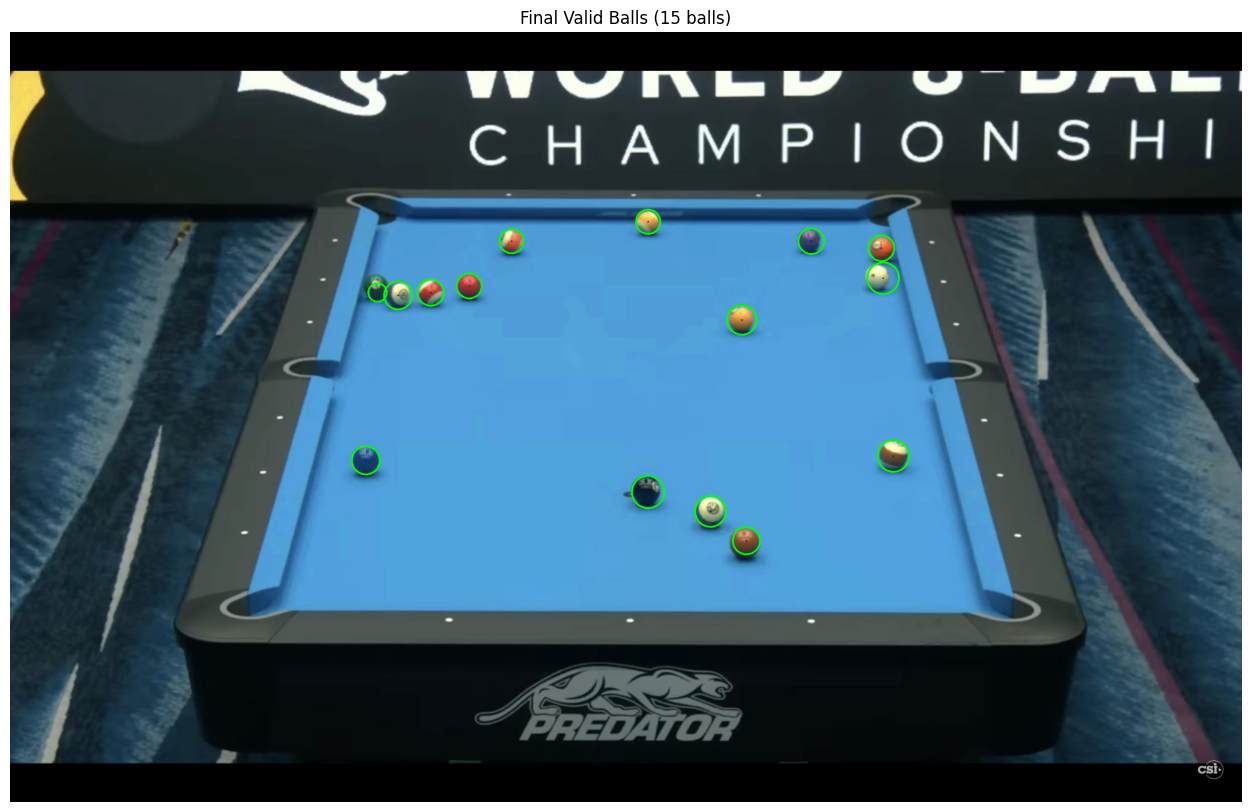

In [249]:

final_result = cv2.cvtColor(state.hsv_image, cv2.COLOR_HSV2RGB)
final_balls = [c for i, c in enumerate(valid_circles) if i not in indices_to_drop]

for (cx, cy, r) in final_balls:
    cv2.circle(final_result, (cx, cy), r, (0, 255, 0), 4)
    cv2.circle(final_result, (cx, cy), 2, (0, 0, 255), -1) 

plt.figure(figsize=(20, 10))
plt.imshow(final_result)
plt.title(f'Final Valid Balls ({len(final_balls)} balls)')
plt.axis('off')
plt.show()

In [250]:
#RGB reference CALIBRATION COLORS (manually sampled from the image)
REFERENCE_COLORS = { 
    "Yellow": np.array([214, 147, 65]),
    "Blue": np.array([24, 67, 115]),
    "Red": np.array([180, 55, 61]),
    "Red_Dark": np.array([138, 52, 56]),
    "Purple": np.array([74, 74, 111]),
    "Orange": np.array([180, 86, 50]),
    "Orange_Bright": np.array([235, 110, 53]),
    "Green":np.array([40, 92, 85]),
    "Brown": np.array([123, 79, 53]),
    "White": np.array([247, 250, 187]),
    "Black": np.array([9, 32, 48]),
}



In [251]:

""""
# 1. Convert your existing HSV image to BGR so OpenCV displays the colors correctly
display_image = cv2.cvtColor(state.hsv_image, cv2.COLOR_HSV2BGR)

# Create a copy so we can draw tiny dots on it when you click
clone = display_image.copy()

def sample_color(event, x, y, flags, param):
    # Only trigger when the left mouse button is clicked
    if event == cv2.EVENT_LBUTTONDOWN:
        # OpenCV reads the display image in BGR format
        bgr_color = display_image[y, x]
        
        # Convert the single BGR pixel to HSV
        hsv_color = cv2.cvtColor(np.uint8([[bgr_color]]), cv2.COLOR_BGR2HSV)[0][0]
        h, s, v = hsv_color[0], hsv_color[1], hsv_color[2]
        
        # Print the exact format you need to copy/paste in HSV
        print(f"np.array([{h}, {s}, {v}]),  # Sampled at ({x}, {y})")
        
        # Draw a tiny green dot where you clicked so you know you got it
        cv2.circle(clone, (x, y), 2, (0, 255, 0), -1)
        cv2.imshow("Manual Color Sampler", clone)

# 2. Set up the interactive window and attach the mouse click event
cv2.namedWindow("Manual Color Sampler")
cv2.setMouseCallback("Manual Color Sampler", sample_color)

print("--- MANUAL COLOR SAMPLER ---")
print("1. Click on the truest color of a ball (avoid the white glare and dark shadows).")
print("2. Copy the printed array from your console.")
print("3. Press 'q' or 'ESC' on your keyboard while the window is selected to close it.")

# 3. Keep the window open until you press 'q'
while True:
    cv2.imshow("Manual Color Sampler", clone)
    key = cv2.waitKey(1) & 0xFF
    
    # Exit loop if 'q' or 'ESC' is pressed
    if key == ord("q") or key == 27:
        break

# Clean up
cv2.destroyAllWindows()
cv2.waitKey(1)"""

'"\n# 1. Convert your existing HSV image to BGR so OpenCV displays the colors correctly\ndisplay_image = cv2.cvtColor(state.hsv_image, cv2.COLOR_HSV2BGR)\n\n# Create a copy so we can draw tiny dots on it when you click\nclone = display_image.copy()\n\ndef sample_color(event, x, y, flags, param):\n    # Only trigger when the left mouse button is clicked\n    if event == cv2.EVENT_LBUTTONDOWN:\n        # OpenCV reads the display image in BGR format\n        bgr_color = display_image[y, x]\n        \n        # Convert the single BGR pixel to HSV\n        hsv_color = cv2.cvtColor(np.uint8([[bgr_color]]), cv2.COLOR_BGR2HSV)[0][0]\n        h, s, v = hsv_color[0], hsv_color[1], hsv_color[2]\n        \n        # Print the exact format you need to copy/paste in HSV\n        print(f"np.array([{h}, {s}, {v}]),  # Sampled at ({x}, {y})")\n        \n        # Draw a tiny green dot where you clicked so you know you got it\n        cv2.circle(clone, (x, y), 2, (0, 255, 0), -1)\n        cv2.imshow("Ma

White and black proportions to classify as "white", "black", "full" or "stripe".

-> For the full group, compare median of pixels
 
->For stripe compare median of non-white pixels

Ball at (1147, 710) | White Ratio: 0.2722 | Black Ratio: 0.0004
Ball at (1996, 785) | White Ratio: 0.0943 | Black Ratio: 0.0339
Ball at (1996, 785)
  -> MEAN sees:   [168.08386207 135.54041379  78.83613793]
  -> MEDIAN sees: [181. 132.  67.]
Ball at (2409, 1156) | White Ratio: 0.2956 | Black Ratio: 0.0419
Ball at (1910, 1307) | White Ratio: 0.7402 | Black Ratio: 0.0572
Ball at (1740, 1254) | White Ratio: 0.0564 | Black Ratio: 0.6166
Ball at (1058, 718) | White Ratio: 0.5192 | Black Ratio: 0.0648
Ball at (1740, 517) | White Ratio: 0.2850 | Black Ratio: 0.0000
Ball at (1252, 692) | White Ratio: 0.0209 | Black Ratio: 0.0000
Ball at (1252, 692)
  -> MEAN sees:   [156.79916318  66.48953975  66.42639787]
  -> MEDIAN sees: [157.  54.  58.]
Ball at (970, 1168) | White Ratio: 0.0125 | Black Ratio: 0.0003
Ball at (970, 1168)
  -> MEAN sees:   [ 34.22156435  74.37363665 119.77157993]
  -> MEDIAN sees: [ 22.  60. 108.]
Ball at (1368, 570) | White Ratio: 0.3298 | Black Ratio: 0.0000
Ball at (2008, 

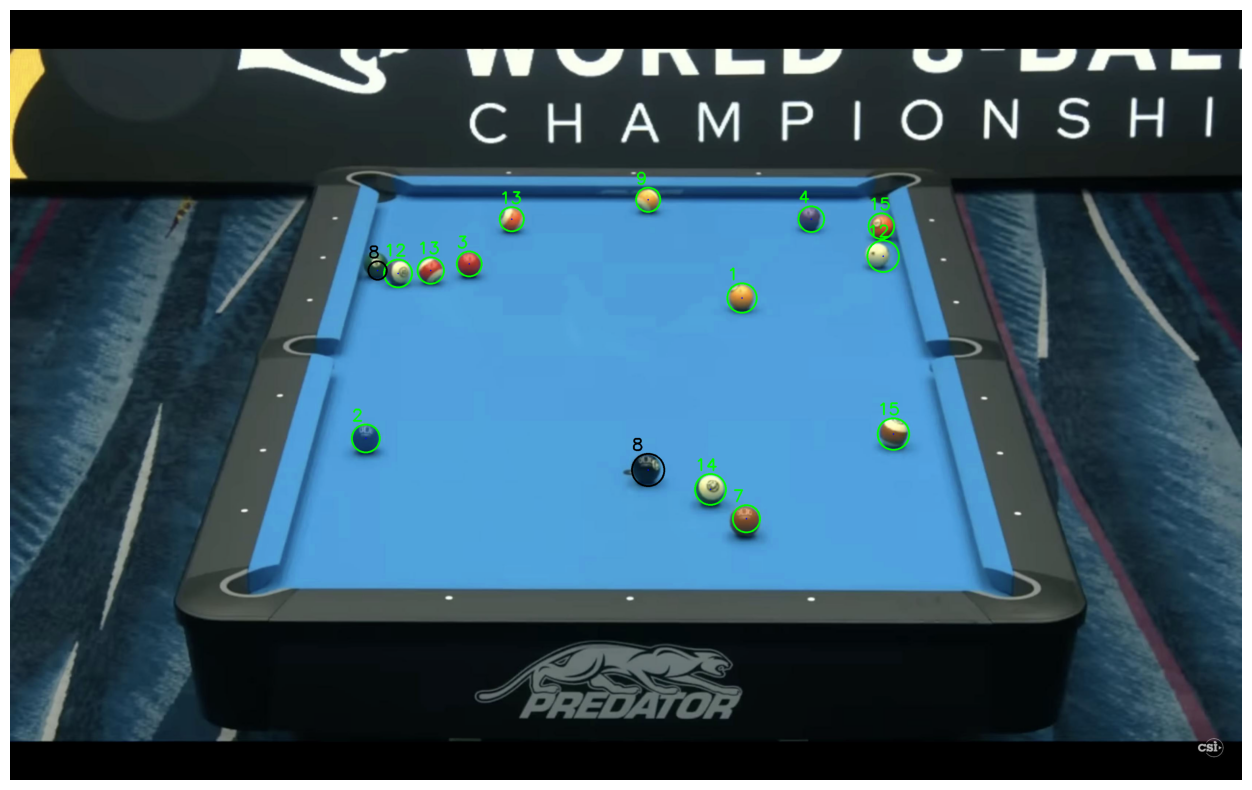

In [252]:
def classify_ball(hsv_img, rgb_img, cx, cy, r):

    mask = np.zeros(hsv_img.shape[:2], dtype=np.uint8)
    cv2.circle(mask, (cx, cy), int(r * 0.86), 255, -1)
    
    hsv_pixels = hsv_img[mask == 255]
    rgb_pixels = rgb_img[mask == 255]
    if len(hsv_pixels) == 0:
        return "Unknown"

    white_rgb_unit8 = np.uint8([[REFERENCE_COLORS["White"]]])
    white_hsv_sample = cv2.cvtColor(white_rgb_unit8, cv2.COLOR_RGB2HSV)[0][0]
    is_white = (hsv_pixels[:, 1] < (white_hsv_sample[1] + 45)) & (hsv_pixels[:, 2] > 130) 
    white_ratio = np.sum(is_white) / len(hsv_pixels)    

    # BLACK
    black_ref = REFERENCE_COLORS["Black"]
    dists_to_black = np.linalg.norm(rgb_pixels - black_ref, axis=1)
    is_black = dists_to_black < 45
    black_ratio = np.sum(is_black) / len(rgb_pixels)


    print(f"Ball at ({cx}, {cy}) | White Ratio: {white_ratio:.4f} | Black Ratio: {black_ratio:.4f}")

    if white_ratio > 0.75:
        return 0
    elif black_ratio > 0.50:
        return 8
    elif white_ratio < 0.2:
        best_color = "Unknown"
        min_dist = float('inf')

        mean_rgb = np.mean(rgb_pixels, axis=0)
        median_rgb = np.median(rgb_pixels, axis=0)

        print(f"Ball at ({cx}, {cy})")
        print(f"  -> MEAN sees:   {mean_rgb}")
        print(f"  -> MEDIAN sees: {median_rgb}")
    #  print(f"Ball at ({cx}, {cy}) actual median RGB is: {median_rgb}")
        for color_name, ref_color in REFERENCE_COLORS.items():
            if color_name in ["White", "Black"]:
                continue         
            dist = np.linalg.norm(median_rgb - ref_color)
            if dist < min_dist:
                min_dist = dist
                best_color = color_name
        SOLID_NUMBERS = {
            "Yellow": 1,
            "Blue": 2,
            "Red": 3,
            "Red_Dark": 3,
            "Purple": 4,
            "Orange": 5,
            "Orange_Bright": 5, 
            "Green": 6,
            "Brown": 7
        }

        # Return the solid number, or "Unknown" if it somehow missed
        return SOLID_NUMBERS.get(best_color, "Unknown")

    else:
        non_white_rgb = rgb_pixels[~is_white]
        if len(non_white_rgb) == 0:
            return "Unknown"
        
        stripe_median_rgb = np.median(non_white_rgb, axis=0) 
        best_stripe_color = "Unknown"
        min_dist = float('inf')   
        for color_name, ref_color in REFERENCE_COLORS.items():
            if color_name in ["White", "Black"]:
                continue         
            dist = np.linalg.norm(stripe_median_rgb - ref_color)
            if dist < min_dist:
                min_dist = dist
                best_stripe_color = color_name        

        STRIPED_NUMBERS = {
            "Yellow": 9,
            "Blue": 10,
            "Red": 11,        
            "Red_Dark": 11,
            "Purple": 12,
            "Orange": 13,
            "Orange_Bright": 13,
            "Green": 14,
            "Brown": 15
        }

        return STRIPED_NUMBERS.get(best_stripe_color, "Unknown")  

      
final_result_render = final_result.copy()


detected_balls_info = [] #<---- BALL INFO IS HERE: list of tuples (ball_id, (cx, cy), r)

for (cx, cy, r) in final_balls:
    ball_id = classify_ball(state.hsv_image, rgb_image, cx, cy, r)
    detected_balls_info.append((ball_id, (cx, cy), r))      

    if ball_id == 0:
        label, color = "0", (255, 255, 255)
    elif ball_id == 8:
        label, color = "8", (0, 0, 0)
    elif ball_id == "Pending":
         label, color = "Pending", (0, 0, 255)
    else:
        label, color = str(ball_id), (0, 255, 0)
    
    cv2.circle(final_result_render, (cx, cy), r, color, 3)
    cv2.putText(final_result_render, label, (cx - r, cy - r - 10), 
                cv2.FONT_HERSHEY_SIMPLEX, 1.5, color, 4)

plt.figure(figsize=(20, 10))
plt.imshow(final_result_render)
plt.axis('off')
plt.show()

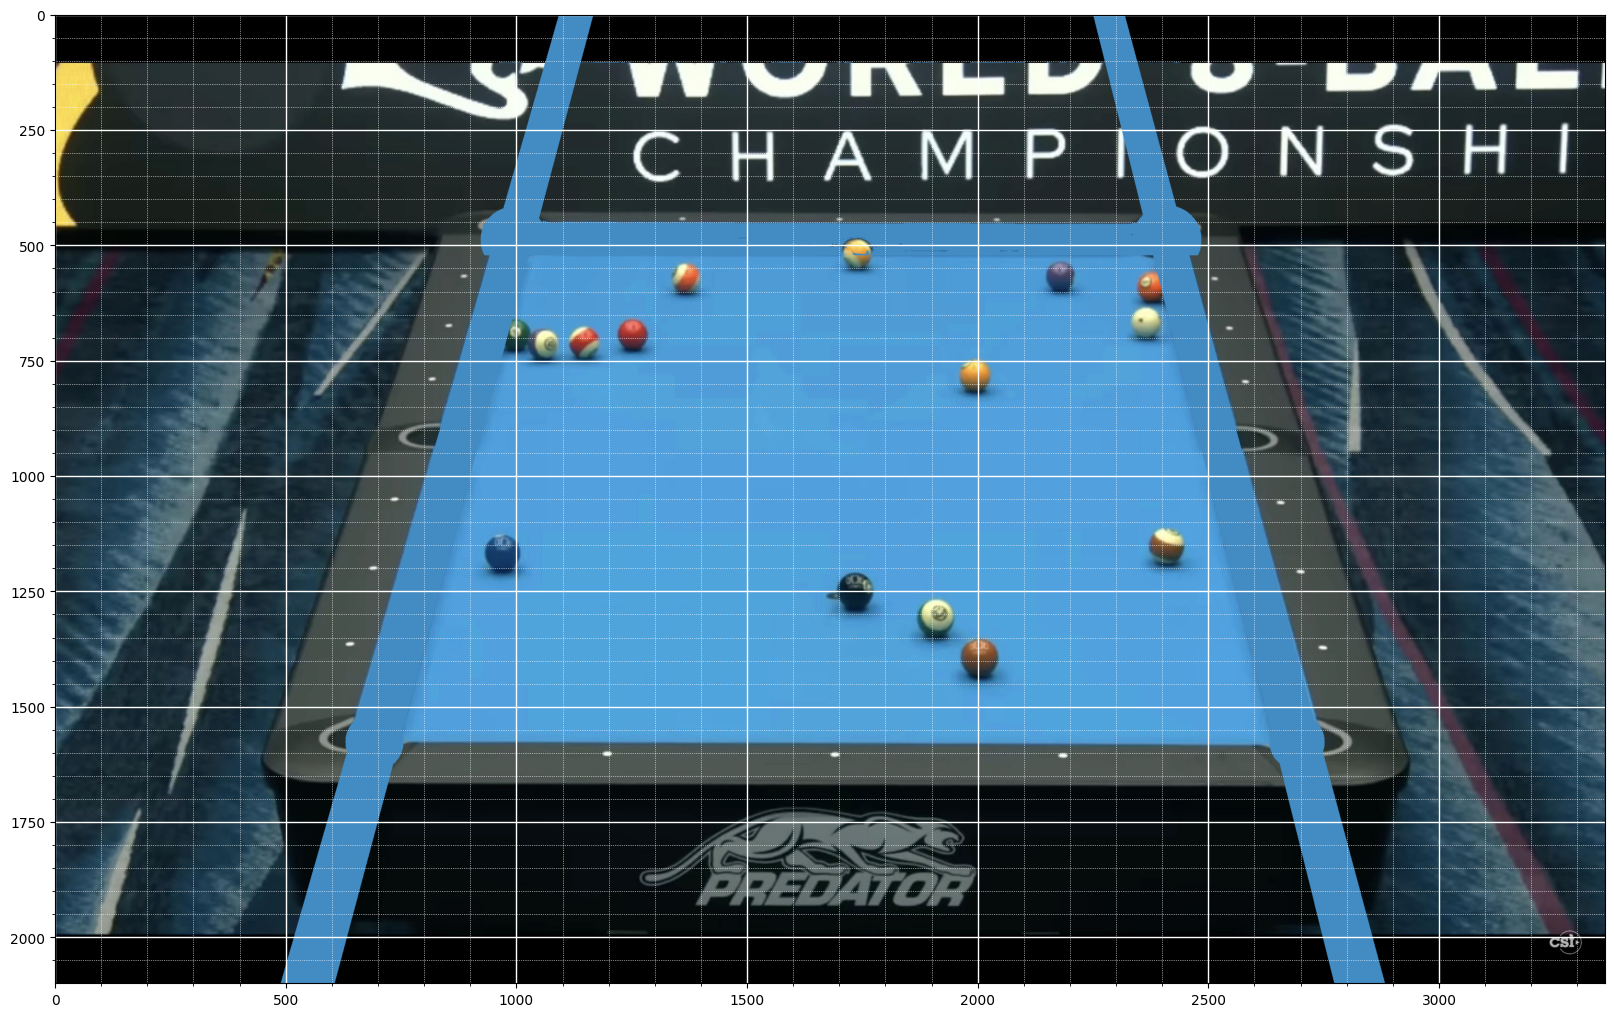

In [253]:

plt.figure(figsize=(20, 15))
plt.imshow(rgb_image)
plt.minorticks_on()
plt.grid(which='major', color='white', linestyle='-', linewidth=1)
plt.grid(which='minor', color='white', linestyle=':', linewidth=0.5)

plt.show()